<a href="https://colab.research.google.com/github/velasquezcalderonrafael32-git/Proyecto-Final-Programacion-Rafael-Velasquez-y-Juan-Martin-Franco/blob/Rama-Rafa/Proyecto_Final_Programaci%C3%B3n_Rafael_Velasquez_y_Juan_Martin_Franco.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##JUAN MARTIN FRANCO - RAFAEL VELASQUEZ

#Calculadora de rentabilidad de domicilios para una panadería en Bogotá y simulador de escenarios



#Instrucciones de ejecución

Descargar el archivo datos_panaderia.xlsx (se encuentra subido en el GitHub).

Cargar el archivo en Google Colab o ubicarlo en la misma carpeta del notebook.

Ejecutar todas las celdas en orden.

Modificar los parámetros de la sección 8 para simular diferentes escenarios de demanda, número de repartidores, tarifas y pedidos mínimos.

Los datos utilizados son ficticios y fueron construidos con fines académicos para representar el funcionamiento de una panadería en Bogotá.

**Nota sobre el uso de inteligencia artificial:** Durante el desarrollo del proyecto utilizamos ChatGPT como herramienta de apoyo para estructurar la simulación de escenarios, comprender algunas funciones de Python y corregir errores en el código. Verificamos sus aportes mediante la ejecución del programa, la revisión de las fórmulas utilizadas y la comparación de los resultados obtenidos en diferentes escenarios.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

datos_panaderia = pd.ExcelFile("datos_panaderia.xlsx")

productos = pd.read_excel(datos_panaderia, sheet_name="Productos").dropna(subset=["Categoría"])
zonas = pd.read_excel(datos_panaderia, sheet_name="Zonas").dropna(subset=["Distancia al negocio (km)"])
parametros = pd.read_excel(datos_panaderia, sheet_name="Parametros")
franjas = pd.read_excel(datos_panaderia, sheet_name="Franjas").dropna(subset=["Horario"])
pedidos = pd.read_excel(datos_panaderia, sheet_name="Pedidos").dropna(subset=["Zona"])
escenarios = pd.read_excel(datos_panaderia, sheet_name="Escenarios")
print(len(productos), "productos |", len(zonas), "zonas |", len(pedidos), "pedidos |", len(escenarios), "escenarios")

10 productos | 8 zonas | 80 pedidos | 6 escenarios


## 2. Parámetros del negocio

In [2]:
valores = dict(zip(parametros["Parámetro"], parametros["Valor"]))

p = {
    "costo_km": valores["Costo por kilómetro (moto)"],
    "pago_hora": valores["Pago al repartidor por hora"],
    "empaque": valores["Costo de empaque por pedido"],
    "comision": valores["Comisión de plataforma"],
    "n_rep": int(valores["Número de repartidores actual"]),
    "prep": valores["Tiempo de preparación de un pedido"],
    "espera_max": valores["Tiempo máximo de espera aceptable"],
    "margen": valores["Margen de ganancia promedio del producto"]
}

print(p)

tiempo_zona = dict(zip(
    zonas["Zona (barrio)"],
    zonas["Tiempo ida y vuelta (min)"]
))

dist_zona = dict(zip(
    zonas["Zona (barrio)"],
    zonas["Distancia al negocio (km)"]
))

{'costo_km': 700.0, 'pago_hora': 12000.0, 'empaque': 800.0, 'comision': 0.0, 'n_rep': 2, 'prep': 12.0, 'espera_max': 45.0, 'margen': 0.62}


## 3. Cálculo de costos y rentabilidad por pedido

In [3]:
def costo_reparto(distancia_km, tiempo_min, valor, p):
    #Costo de entregar un pedido (en COP)
    km = distancia_km * 2 * p["costo_km"]            # ida y vuelta
    mano_obra = tiempo_min / 60 * p["pago_hora"]
    comision = valor * p["comision"]
    return km + mano_obra + p["empaque"] + comision


def ganancia_pedido(valor, tarifa, costo, p):
    #Margen de los productos + tarifa cobrada - costo de reparto.
    return valor * p["margen"] + tarifa - costo


# Se calcula el costo de reparto y la ganancia de cada pedido usando las funciones definidas arriba
costos, ganancias = [], []
for _, fila in pedidos.iterrows():
    zona = fila["Zona"]
    c = costo_reparto(dist_zona[zona], tiempo_zona[zona], fila["Valor productos (COP)"], p)
    g = ganancia_pedido(fila["Valor productos (COP)"], fila["Tarifa cobrada (COP)"], c, p)
    costos.append(c)
    ganancias.append(g)

pedidos["Costo reparto"] = costos
pedidos["Ganancia"] = ganancias
pedidos["Rentable"] = pedidos["Ganancia"] > 0

print("Pedidos rentables:", (pedidos['Rentable']).sum(), "de", len(pedidos))
pedidos.head()

Pedidos rentables: 60 de 80


,ID pedido,Día,Franja,Zona,N.º productos,Valor productos (COP),Distancia (km),Tarifa cobrada (COP),Costo reparto,Ganancia,Rentable
0,P001,Sábado,Mañana,Chapinero Central,1.0,5500.0,2.5,3500.0,9100.0,-2190.0,False
1,P002,Martes,Noche,Teusaquillo,1.0,116000.0,4.0,4500.0,13200.0,63220.0,True
2,P003,Sábado,Mediodía,Chapinero Alto,2.0,18800.0,1.5,3000.0,6500.0,8156.0,True
3,P004,Domingo,Mediodía,Teusaquillo,1.0,3000.0,4.0,4500.0,13200.0,-6840.0,False
4,P005,Miércoles,Mañana,Chapinero Alto,5.0,42300.0,1.5,3000.0,6500.0,22726.0,True


## 4. Propuesta de tarifas y pedidos mínimos

In [4]:
def redondear_arriba(x, paso=500):
    return int(np.ceil(x / paso) * paso)


def propuesta_tarifas(AUMENTO_MAX=4000):

    resumen = pedidos.groupby("Zona").agg(
        pedidos=("ID pedido", "count"),
        valor_prom=("Valor productos (COP)", "mean"),
        tarifa_actual=("Tarifa cobrada (COP)", "mean"),
        costo_prom=("Costo reparto", "mean"),
        ganancia_total=("Ganancia", "sum"),
        ganancia_prom=("Ganancia", "mean"),
    ).reset_index()

    sug_tarifa = []
    sug_minimo = []

    for _, f in resumen.iterrows():

        # Margen promedio obtenido por la venta de productos
        margen = f["valor_prom"] * p["margen"]

        # Tarifa necesaria para no perder dinero
        tarifa_equilibrio = f["costo_prom"] - margen

        tarifa = f["tarifa_actual"]

        # Solo aumentar la tarifa en zonas con pérdidas
        if f["ganancia_prom"] < 0:
            tarifa = redondear_arriba(tarifa_equilibrio)
            tarifa = min(tarifa, f["tarifa_actual"] + AUMENTO_MAX)
            tarifa = max(tarifa, f["tarifa_actual"])

        sug_tarifa.append(tarifa)

        # Pedido mínimo necesario para cubrir los costos
        faltante = f["costo_prom"] - tarifa

        pedido_min = max(0, faltante / p["margen"])
        pedido_min = redondear_arriba(pedido_min, 1000)

        sug_minimo.append(pedido_min)

    resumen["tarifa_sugerida"] = sug_tarifa
    resumen["pedido_min_sugerido"] = sug_minimo

    # Simulación

    sim = pedidos.merge(
        resumen[["Zona", "tarifa_sugerida", "pedido_min_sugerido"]],
        on="Zona"
    )

    # Identificar pedidos que cumplen con el mínimo
    sim["Aceptado"] = (
        sim["Valor productos (COP)"] >= sim["pedido_min_sugerido"]
    )

    # Calcular la ganancia de cada pedido
    sim["Ganancia sim"] = (
        sim["Valor productos (COP)"] * p["margen"]
        + sim["tarifa_sugerida"]
        - sim["Costo reparto"]
    )

    # Los pedidos rechazados no generan ganancias ni costos
    sim.loc[sim["Aceptado"] == False, "Ganancia sim"] = 0

    resumen["ganancia_total_sim"] = resumen["Zona"].map(
        sim.groupby("Zona")["Ganancia sim"].sum()
    )

    resumen["ganancia_prom_sim"] = resumen["Zona"].map(
        sim.groupby("Zona")["Ganancia sim"].mean()
    )

    resumen["pedidos_aceptados"] = resumen["Zona"].map(
        sim.groupby("Zona")["Aceptado"].sum()
    )

    resumen = resumen.sort_values("ganancia_prom").round(0)

    tabla1 = resumen[[
        "Zona", "pedidos", "valor_prom", "tarifa_actual",
        "costo_prom", "ganancia_total", "ganancia_prom",
        "tarifa_sugerida", "pedido_min_sugerido",
        "pedidos_aceptados", "ganancia_total_sim",
        "ganancia_prom_sim"
    ]].copy()

    tabla1.columns = [
        "Zona", "Pedidos", "Valor prom.", "Tarifa actual",
        "Costo reparto prom.", "Ganancia total", "Ganancia prom.",
        "Tarifa sugerida", "Pedido mín. sugerido",
        "Pedidos aceptados", "Ganancia total simulada",
        "Ganancia prom. simulada"
    ]

    return resumen, sim, tabla1

AUMENTO_MAX = 4000 #@param {type:"slider", min:0, max:10000, step:500}

resumen, sim, tabla1 = propuesta_tarifas(AUMENTO_MAX)

tabla1

,Zona,Pedidos,Valor prom.,Tarifa actual,Costo reparto prom.,Ganancia total,Ganancia prom.,Tarifa sugerida,Pedido mín. sugerido,Pedidos aceptados,Ganancia total simulada,Ganancia prom. simulada
7,Usaquén,8,14325.0,7000.0,23000.0,-56948.0,-7118.0,11000.0,20000,3,15770.0,1971.0
0,Cedritos,3,43600.0,9000.0,30200.0,17496.0,5832.0,9000.0,35000,1,32120.0,10707.0
5,Suba,6,62433.0,11000.0,37400.0,73852.0,12309.0,11000.0,43000,3,104134.0,17356.0
6,Teusaquillo,10,48190.0,4500.0,13200.0,211778.0,21178.0,4500.0,15000,7,229012.0,22901.0
1,Chapinero Alto,20,41945.0,3000.0,6500.0,450118.0,22506.0,3000.0,6000,19,451882.0,22594.0
2,Chapinero Central,16,48106.0,3500.0,9100.0,387614.0,24226.0,3500.0,10000,14,392924.0,24558.0
4,Rosales,9,58833.0,4000.0,10600.0,268890.0,29877.0,4000.0,11000,8,271894.0,30210.0
3,Chicó,8,83938.0,5000.0,15800.0,329930.0,41241.0,5000.0,18000,7,332670.0,41584.0


## 5. Comparación de rentabilidad por zona

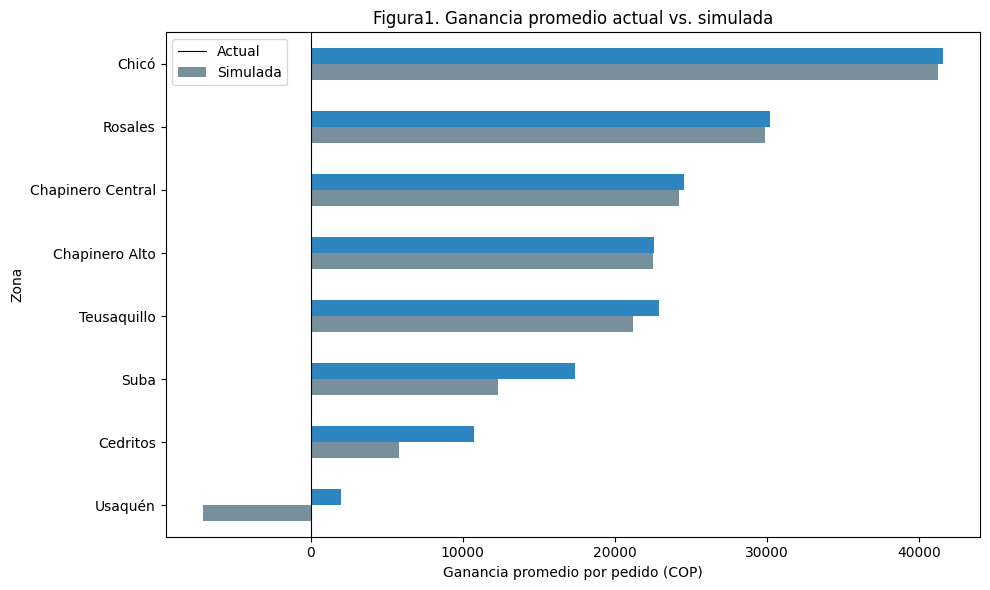

In [5]:
resumen.plot.barh(
    x="Zona",
    y=["ganancia_prom", "ganancia_prom_sim"],
    figsize=(10, 6),
    color=["#78909C", "#2E86C1"]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Figura1. Ganancia promedio actual vs. simulada")
plt.xlabel("Ganancia promedio por pedido (COP)")
plt.ylabel("Zona")
plt.legend(["Actual", "Simulada"])
plt.tight_layout()
plt.show()

## 6. Simulación por franjas horarias


In [6]:
nombres_zona = list(zonas["Zona (barrio)"])

prob_zona = np.array(zonas["% de pedidos"], dtype=float)
prob_zona = prob_zona / prob_zona.sum()

valores_pedidos = pedidos["Valor productos (COP)"].to_numpy()

## AYUDA DE IA

valores_zona = {
    z: pedidos.loc[
        pedidos["Zona"] == z, "Valor productos (COP)"
    ].to_numpy()
    for z in nombres_zona
}

tarifa_zona = dict(zip(
    zonas["Zona (barrio)"],
    zonas["Tarifa de envío actual (COP)"]
))


def simular_franja(n_pedidos, duracion_h, libres, rng, p,
                   inicio_franja, cierre, esc):

    minutos = duracion_h * 60

    llegadas = np.sort(
        rng.uniform(inicio_franja, inicio_franja + minutos, n_pedidos)
    )

    atendidos = []
    tardios = 0
    pendientes = 0
    rechazados = 0

    for llegada in llegadas:

        # Seleccionar zona y valor del pedido
        zona = rng.choice(nombres_zona, p=prob_zona)

        valores_z = valores_zona[zona]

        if len(valores_z) == 0:
            valores_z = valores_pedidos

        valor = rng.choice(valores_z)

        # Tarifa y pedido mínimo del escenario
        tarifa = tarifa_zona[zona] * (
            1 + esc["Cambio en tarifa de envío (%)"]
        )

        pedido_min = esc["Pedido mínimo (COP)"]

        # Aplicar la propuesta de tarifas por zona
        if esc["Escenario"] == "Tarifas y mínimos sugeridos":

            fila = resumen.loc[resumen["Zona"] == zona].iloc[0]

            tarifa = fila["tarifa_sugerida"]
            pedido_min = fila["pedido_min_sugerido"]

        # Rechazar pedidos que no cumplen el mínimo
        if valor < pedido_min:
            rechazados += 1
            continue

        # Buscar al primer repartidor disponible
        i = libres.index(min(libres))

        inicio = max(llegada + p["prep"], libres[i])

        t_total = tiempo_zona[zona]

        # Verificar si puede completar el reparto antes del cierre
        if inicio + t_total > cierre:
            pendientes += 1
            continue

        # Actualizar la disponibilidad del repartidor
        libres[i] = inicio + t_total

        atendidos.append([zona, valor, tarifa])

        # Verificar tiempo de entrega al cliente
        espera = inicio + t_total / 2 - llegada

        if espera > p["espera_max"]:
            tardios += 1

    return atendidos, tardios, pendientes, rechazados


# Ejemplo: simulación por franja en un día normal
rng = np.random.default_rng(1)

libres = [0.0] * p["n_rep"]

inicio_franja = 0
cierre = franjas["Duración (horas)"].sum() * 60

esc_base = {
    "Escenario": "Base",
    "Cambio en tarifa de envío (%)": 0,
    "Pedido mínimo (COP)": 0
}

filas = []

for _, fr in franjas.iterrows():

    n = int(fr["Pedidos esperados (día normal)"])

    at, tard, pend, rech = simular_franja(
        n, fr["Duración (horas)"], libres, rng, p,
        inicio_franja, cierre, esc_base
    )

    filas.append([
        fr["Franja"], n, len(at), tard, pend, rech
    ])

    inicio_franja += fr["Duración (horas)"] * 60


pd.DataFrame(filas, columns=[
    "Franja", "Pedidos que llegan", "Atendidos",
    "Tardíos", "Pendientes", "Rechazados"
])

,Franja,Pedidos que llegan,Atendidos,Tardíos,Pendientes,Rechazados
0,Mañana,14,14,8,0,0
1,Mediodía,8,8,2,0,0
2,Tarde,6,6,1,0,0
3,Noche,12,8,3,4,0


## 7. Simulación y comparación de escenarios

In [7]:
def simular_dia(esc, rng, p):

    n_rep = int(esc["Repartidores"])

    ingresos = 0
    costos_var = 0

    llegan = 0
    atendidos_tot = 0
    tardios_tot = 0
    pendientes_tot = 0
    rechazados = 0

    # Disponibilidad de los repartidores durante todo el día
    libres = [0.0] * n_rep

    inicio_franja = 0
    horas_dia = franjas["Duración (horas)"].sum()
    cierre = horas_dia * 60

    for _, fr in franjas.iterrows():

        n = int(round(
            fr["Pedidos esperados (día normal)"]
            * esc["Factor de demanda"]
        ))

        llegan += n

        at, tard, pend, rech = simular_franja(
            n, fr["Duración (horas)"], libres, rng, p,
            inicio_franja, cierre, esc
        )

        atendidos_tot += len(at)
        tardios_tot += tard
        pendientes_tot += pend
        rechazados += rech

        # Calcular ingresos y costos de los pedidos atendidos
        for zona, valor, tarifa in at:

            ingresos += valor * p["margen"] + tarifa

            costos_var += (
                dist_zona[zona] * 2 * p["costo_km"]
                + p["empaque"]
                + valor * p["comision"]
            )

        inicio_franja += fr["Duración (horas)"] * 60

    # Costo de los repartidores por toda la jornada
    costo_repartidores = n_rep * horas_dia * p["pago_hora"]

    ganancia = ingresos - costos_var - costo_repartidores

    return {
        "llegan": llegan,
        "atendidos": atendidos_tot,
        "tardíos": tardios_tot,
        "pendientes": pendientes_tot,
        "rechazados": rechazados,
        "ganancia": ganancia
    }


# Añadir la propuesta de tarifas como un nuevo escenario
nuevo_escenario = {
    "Escenario": "Tarifas y mínimos sugeridos",
    "Repartidores": p["n_rep"],
    "Factor de demanda": 1,
    "Cambio en tarifa de envío (%)": 0,
    "Pedido mínimo (COP)": 0
}

escenarios_sim = pd.concat([
    escenarios,
    pd.DataFrame([nuevo_escenario])
], ignore_index=True)


# Comparar los escenarios durante 200 días
N_DIAS = 200

filas = []

for _, esc in escenarios_sim.iterrows():

    rng = np.random.default_rng(42)

    dias = [
        simular_dia(esc, rng, p)
        for _ in range(N_DIAS)
    ]

    prom = pd.DataFrame(dias).mean()

    filas.append([
        esc["Escenario"],
        int(esc["Repartidores"]),
        prom["llegan"],
        prom["atendidos"],
        prom["tardíos"],
        prom["pendientes"],
        prom["rechazados"],
        prom["ganancia"]
    ])

comparacion = pd.DataFrame(filas, columns=[
    "Escenario",
    "Repartidores",
    "Pedidos que llegan",
    "Atendidos",
    "Tardíos",
    "Pendientes",
    "Rechazados (pedido mín.)",
    "Ganancia diaria (COP)"
]).round(0)

comparacion

,Escenario,Repartidores,Pedidos que llegan,Atendidos,Tardíos,Pendientes,Rechazados (pedido mín.),Ganancia diaria (COP)
0,Base,2,40.0,35.0,18.0,5.0,0.0,618537.0
1,Demanda alta,2,60.0,46.0,41.0,14.0,0.0,946605.0
2,Más repartidores,3,60.0,53.0,24.0,7.0,0.0,955395.0
3,Menos repartidores,1,40.0,23.0,21.0,17.0,0.0,462353.0
4,Tarifa +20%,2,40.0,35.0,18.0,5.0,0.0,654139.0
5,Pedido mínimo $25.000,2,40.0,20.0,6.0,2.0,18.0,559395.0
6,Tarifas y mínimos sugeridos,2,40.0,27.0,6.0,3.0,10.0,624096.0


##7.1 Simulación y comparación de escenarios
## (Grafica de promedio de ganancia diaria en cada escenario)

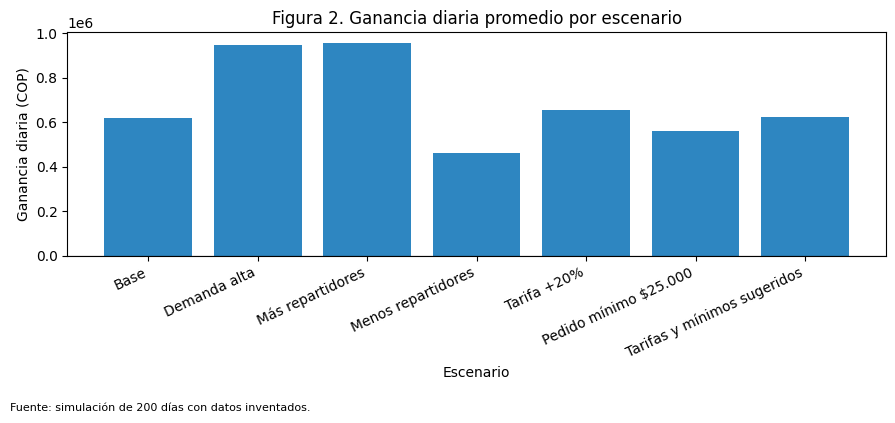

Escenario más rentable: Más repartidores con $955,395 diarios
  Pedidos tardíos: 24.0 | pendientes: 7.0


In [8]:
# Figura 2: ganancia diaria por escenario

colores = ["#C0392B" if g < 0 else "#2E86C1" for g in comparacion["Ganancia diaria (COP)"]]
plt.figure(figsize=(9, 4))
plt.bar(comparacion["Escenario"], comparacion["Ganancia diaria (COP)"], color=colores)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Figura 2. Ganancia diaria promedio por escenario")
plt.xlabel("Escenario")
plt.ylabel("Ganancia diaria (COP)")
plt.xticks(rotation=25, ha="right")
plt.figtext(0.01, -0.04, "Fuente: simulación de 200 días con datos inventados.", fontsize=8)
plt.tight_layout()
plt.show()

mejor = comparacion.loc[comparacion["Ganancia diaria (COP)"].idxmax()]
print(f"Escenario más rentable: {mejor['Escenario']} con ${mejor['Ganancia diaria (COP)']:,.0f} diarios")
print(f"  Pedidos tardíos: {mejor['Tardíos']} | pendientes: {mejor['Pendientes']}")

## 8. Simulador interactivo personalizado

In [9]:
#Parámetros modificables del escenario personalizado

REPARTIDORES = 3 #@param {type:"slider", min:1, max:5, step:1}

DEMANDA = 100 #@param {type:"slider", min:50, max:200, step:10}

AUMENTO_TARIFA = 0 #@param {type:"slider", min:0, max:50, step:5}

PEDIDO_MINIMO = 0 #@param {type:"slider", min:0, max:50000, step:1000}


esc_personalizado = {
    "Escenario": "Personalizado",
    "Repartidores": REPARTIDORES,
    "Factor de demanda": DEMANDA / 100,
    "Cambio en tarifa de envío (%)": AUMENTO_TARIFA / 100,
    "Pedido mínimo (COP)": PEDIDO_MINIMO
}

rng = np.random.default_rng(42)

dias = [
    simular_dia(esc_personalizado, rng, p)
    for _ in range(N_DIAS)
]

resultado = pd.DataFrame(dias).mean()

print("RESULTADOS DEL ESCENARIO PERSONALIZADO")
print("--------------------------------------")
print("Repartidores:", REPARTIDORES)
print("Pedidos recibidos:", round(resultado["llegan"], 1))
print("Pedidos atendidos:", round(resultado["atendidos"], 1))
print("Pedidos tardíos:", round(resultado["tardíos"], 1))
print("Pedidos pendientes:", round(resultado["pendientes"], 1))
print("Pedidos rechazados:", round(resultado["rechazados"], 1))
print("Ganancia diaria:", round(resultado["ganancia"], 0), "COP")

RESULTADOS DEL ESCENARIO PERSONALIZADO
--------------------------------------
Repartidores: 3
Pedidos recibidos: 40.0
Pedidos atendidos: 36.2
Pedidos tardíos: 8.6
Pedidos pendientes: 3.8
Pedidos rechazados: 0.0
Ganancia diaria: 476258.0 COP


CONCLUSIONES/LIMITACIONES


## 9. Conclusiones

Con los datos ficticios que construimos, encontramos que 60 de los 80 pedidos fueron rentables y que Usaquén fue la única zona que presentó pérdidas en promedio. Esto nos permitió identificar que la rentabilidad de un domicilio no depende únicamente de la distancia, sino también del valor de los productos que compra el cliente.

Al implementar las tarifas y los pedidos mínimos sugeridos, la ganancia de los pedidos analizados aumentó de 1.682.730 a $1.830.406, lo que representa una mejora del 8,78%. Sin embargo, bajo el comportamiento supuesto de los consumidores, se rechazaron 18 pedidos.

En la simulación de días completos, el escenario más rentable fue el de demanda alta con un repartidor adicional, con una ganancia diaria promedio de $955.395. También encontramos que la propuesta de tarifas y pedidos mínimos aumentó ligeramente la ganancia diaria frente al escenario base y redujo considerablemente los pedidos tardíos.

Más aun, descubrimos que la demanda alta mas repartidores, aunque no incremento las ganancias significativamente, mejor la calidad de servicio.

Por lo tanto, recomendamos establecer tarifas y pedidos mínimos según las características de cada zona, ajustar la cantidad de repartidores según la demanda y evaluar la reacción de los clientes antes de implementar estos cambios.

## 10. Limitaciones

Los datos son ficticios, así que los resultados no se pueden tomar como la realidad.

Usamos tiempos y distancias fijos por zona, pero en la vida real el tráfico o la lluvia los cambian.

Supusimos cómo reaccionan los clientes. Solo dejan de pedir si no llegan al mínimo, y no tuvimos en cuenta que se puedan ir a la competencia si suben la tarifa.

La simulación es sencilla. No consideramos que un repartidor lleve varios pedidos en un viaje, ni descansos o imprevistos.

Los repartidores se cobran distinto en dos partes del código: por tiempo de viaje en el análisis por pedido y por todas las horas en la simulación diaria, así que esas ganancias no son del todo comparables.

Los resultados cambian un poco en cada corrida por el azar, aunque repetimos 200 días para sacar un promedio.

No incluimos otros costos de la panadería, como arriendo o servicios.